In [1]:
import pandas as pd
import numpy as np


import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression,LogisticRegressionCV

from sklearn.svm import SVC

from sklearn.neighbors import KNeighborsClassifier

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import (plot_tree, export_text)

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier,AdaBoostClassifier,BaggingClassifier

import sklearn.model_selection as skm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

import warnings
warnings.filterwarnings('ignore')

link to the data source:
https://www.kaggle.com/datasets/umerrtx/machine-failure-prediction-using-sensor-data

**Dataset Overview**
<br>This dataset contains sensor data collected from **various machines**, with the aim of predicting machine failures in advance. It includes a variety of sensor readings as well as the recorded machine failures.

Columns Description
<ul>
    <li>footfall: The number of people or objects passing by the machine.</li>
    <li>tempMode: The temperature mode or setting of the machine.</li>
    <li>AQ: Air quality index near the machine.</li>
    <li>USS: Ultrasonic sensor data, indicating proximity measurements.</li>
    <li>CS: Current sensor readings, indicating the electrical current usage of the machine.</li>
    <li>VOC: Volatile organic compounds level detected near the machine.</li>
    <li>RP: Rotational position or RPM (revolutions per minute) of the machine parts.</li>
    <li>IP: Input pressure to the machine.</li>
    <li>Temperature: The operating temperature of the machine.</li>
    <li>fail: Binary indicator of machine failure (1 for failure, 0 for no failure).</li>
</ul>

In [2]:
%%html
<style type="text/css">
.findings {background-color: #cdf7f7; padding: 15px;}
.notes {background-color: #d8f5c4; padding: 15px;}
</style>

In [3]:
data_file = 'machine_failures_data.csv'

In [4]:
# read the csv file
data = pd.read_csv(data_file)

In [5]:
# display dataset to understand the structure
data

,footfall,tempMode,AQ,USS,CS,VOC,RP,IP,Temperature,fail
0,0,7,7,1,6,6,36,3,1,1
1,190,1,3,3,5,1,20,4,1,0
2,31,7,2,2,6,1,24,6,1,0
3,83,4,3,4,5,1,28,6,1,0
4,640,7,5,6,4,0,68,6,1,0
...,...,...,...,...,...,...,...,...,...,...
939,0,7,7,1,6,4,73,6,24,1
940,0,7,5,2,6,6,50,6,24,1
941,0,3,6,2,7,5,43,6,24,1
942,0,6,6,2,5,6,46,7,24,1


## which data points shows machine failure?

In [6]:
data[data['fail'] == 1]

,footfall,tempMode,AQ,USS,CS,VOC,RP,IP,Temperature,fail
0,0,7,7,1,6,6,36,3,1,1
12,190,2,5,4,6,5,22,4,1,1
18,33,7,6,2,6,5,51,4,1,1
23,0,7,6,1,6,6,44,4,2,1
34,640,7,7,5,7,4,33,3,3,1
...,...,...,...,...,...,...,...,...,...,...
939,0,7,7,1,6,4,73,6,24,1
940,0,7,5,2,6,6,50,6,24,1
941,0,3,6,2,7,5,43,6,24,1
942,0,6,6,2,5,6,46,7,24,1


## data pre-processing

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 944 entries, 0 to 943
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   footfall     944 non-null    int64
 1   tempMode     944 non-null    int64
 2   AQ           944 non-null    int64
 3   USS          944 non-null    int64
 4   CS           944 non-null    int64
 5   VOC          944 non-null    int64
 6   RP           944 non-null    int64
 7   IP           944 non-null    int64
 8   Temperature  944 non-null    int64
 9   fail         944 non-null    int64
dtypes: int64(10)
memory usage: 73.9 KB


<div class = "notes">
    <b>Notes</b>
    <br>Consider to rename some columns so that they are easier to understand.
</div>

In [8]:
"""
data = data.rename(columns = {
    'AQ': 'air_quality',
    'USS': 'ultrasonic',
    'CS': 'current',
    'VOC': 'volatile_organic',
    'RP': 'rotational_pos',
    'IP': 'input_pressure'
    })
"""

"\ndata = data.rename(columns = {\n    'AQ': 'air_quality',\n    'USS': 'ultrasonic',\n    'CS': 'current',\n    'VOC': 'volatile_organic',\n    'RP': 'rotational_pos',\n    'IP': 'input_pressure'\n    })\n"

### check null values and duplicates

In [9]:
data.isnull().sum()

footfall       0
tempMode       0
AQ             0
USS            0
CS             0
VOC            0
RP             0
IP             0
Temperature    0
fail           0
dtype: int64

In [10]:
data.duplicated().sum()

np.int64(1)

In [11]:
# find the duplicated rows
data[data.duplicated(keep = False)]

,footfall,tempMode,AQ,USS,CS,VOC,RP,IP,Temperature,fail
730,31,5,3,3,6,1,48,6,21,0
766,31,5,3,3,6,1,48,6,21,0


<div class = "findings">
    <b>Findings</b>
    <br>I don't have enough information to decide if I shall remove one of the duplicated rows.
</div>

### understand data types and unique values per column

In [12]:
data.dtypes

footfall       int64
tempMode       int64
AQ             int64
USS            int64
CS             int64
VOC            int64
RP             int64
IP             int64
Temperature    int64
fail           int64
dtype: object

In [13]:
data.nunique()

footfall       99
tempMode        8
AQ              7
USS             7
CS              7
VOC             7
RP             71
IP              7
Temperature    24
fail            2
dtype: int64

<div class = "findings">
    <b>Findings</b>
    <br>6 columns have categorical data and they have been converted into numeric values:
    <ol>
        <li> tempMode</li>
        <li> AQ</li>
        <li> USS</li>
        <li> CS</li>
        <li> VOC</li>
        <li> IP</li>
    </ol>
</div>

<div class = "notes">
    <b>Notes</b>
    <br>Randomly check two categorical data columns.
</div>

In [14]:
data['tempMode'].value_counts()

tempMode
7    288
0    161
2    112
3    101
1    100
5     84
4     66
6     32
Name: count, dtype: int64

In [15]:
data['AQ'].value_counts()

AQ
4    256
6    218
5    170
3    147
2    103
7     34
1     16
Name: count, dtype: int64

## Feature Engineering

<div class = "notes">
    <b>Notes</b>
    <br>Do I need to create new columns or drop any existing columns? If so, why?
</div>

## Statistical Description

In [16]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
footfall,944.0,306.381356,1082.606745,0.0,1.0,22.0,110.0,7300.0
tempMode,944.0,3.727754,2.677235,0.0,1.0,3.0,7.0,7.0
AQ,944.0,4.325212,1.438436,1.0,3.0,4.0,6.0,7.0
USS,944.0,2.939619,1.383725,1.0,2.0,3.0,4.0,7.0
CS,944.0,5.394068,1.269349,1.0,5.0,6.0,6.0,7.0
VOC,944.0,2.842161,2.273337,0.0,1.0,2.0,5.0,6.0
RP,944.0,47.043432,16.423130,19.0,34.0,44.0,58.0,91.0
IP,944.0,4.565678,1.599287,1.0,3.0,4.0,6.0,7.0
Temperature,944.0,16.331568,5.974781,1.0,14.0,17.0,21.0,24.0
fail,944.0,0.416314,0.493208,0.0,0.0,0.0,1.0,1.0


# Exploratory Data Analysis

## 1. Plotting the Distribution of fail

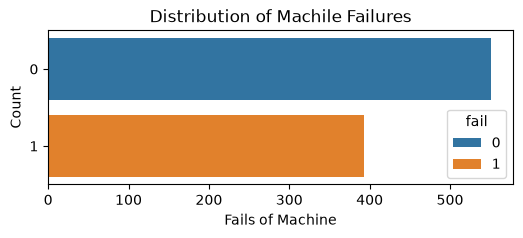

In [17]:
plt.figure(figsize=(6,2))
sns.countplot(y='fail', hue = 'fail', data=data)
plt.title('Distribution of Machile Failures')
plt.xlabel('Fails of Machine')
plt.ylabel('Count')
plt.show()

<div class = "notes">
    Note:
    <br> The distribution of fail data (target output) seems balanced enough.
    <br> No action needed to adjust for imbalanced output data.
</div>

## 2. Plotting the Distribution of tempMode

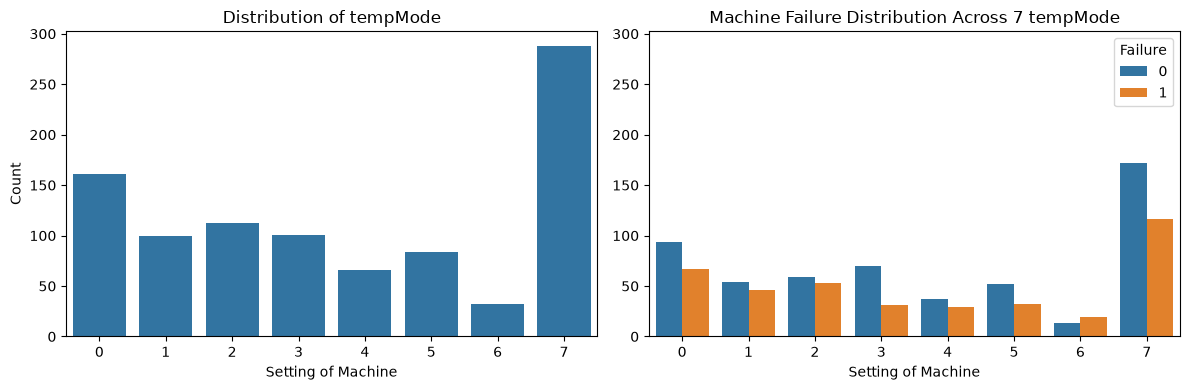

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4), sharey = True)

# distribution of all tempMode data
sns.countplot(x='tempMode', data=data, ax = ax1)
ax1.set_title('Distribution of tempMode')
ax1.set_xlabel('Setting of Machine')
ax1.set_ylabel('Count')

# stacked bars by fail or not
sns.countplot(x='tempMode', hue='fail', data=data, ax = ax2)
ax2.set_title('Machine Failure Distribution Across 7 tempMode')
ax2.set_xlabel('Setting of Machine')
ax2.tick_params(labelleft = True)
plt.legend(title='Failure')

plt.tight_layout()
plt.show()

<div class = "notes">
    Note:
    <br> Most of tempMode data seems to fall in the setting of 7.
    <br> The plot on the right shows that the distribution of fail data seems to distribute across all settings..
</div>

## 3. Plotting the Distribution of AQ Air Quality

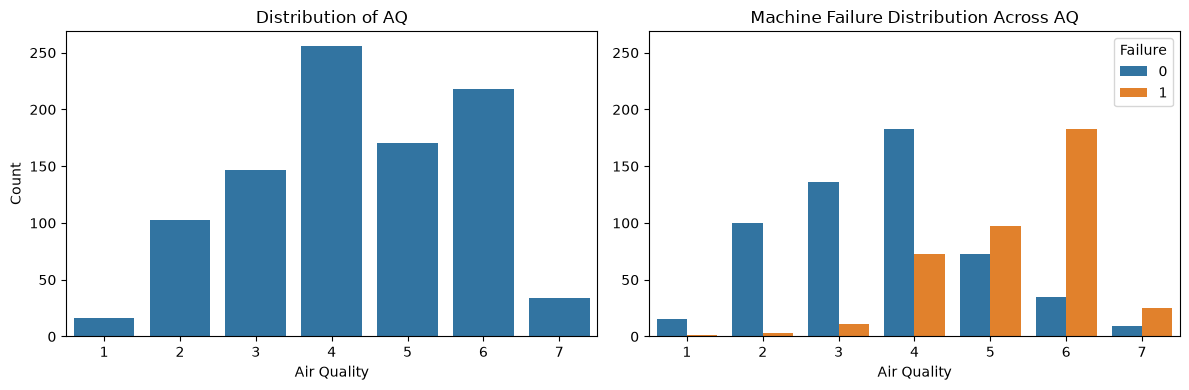

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4), sharey = True)

# distribution of all data
sns.countplot(x='AQ', data=data, ax = ax1)
ax1.set_title('Distribution of AQ')
ax1.set_xlabel('Air Quality')
ax1.set_ylabel('Count')

# stacked bars by fail or not
sns.countplot(x='AQ', hue='fail', data=data, ax = ax2)
ax2.set_title('Machine Failure Distribution Across AQ')
ax2.set_xlabel('Air Quality')
ax2.tick_params(labelleft = True)
plt.legend(title='Failure')

plt.tight_layout()
plt.show()

<div class = "notes">
    Note:
    <br> Air Quality AQ data seems have normal distribution with most data falls in the middle of 4.
    <br> The plot on the right shows that the distribution of fail data seems to spread mostly between 4 and 6.
</div>

## 4. Plotting the Distribution of USS Ultrasonic Sensor

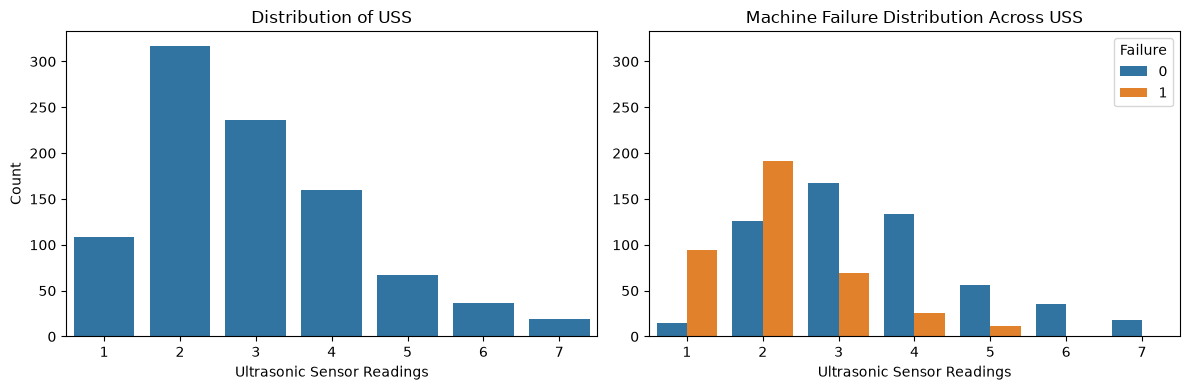

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4), sharey = True)

# distribution of all data
sns.countplot(x='USS', data=data, ax = ax1)
ax1.set_title('Distribution of USS')
ax1.set_xlabel('Ultrasonic Sensor Readings')
ax1.set_ylabel('Count')

# stacked bars by fail or not
sns.countplot(x='USS', hue='fail', data=data, ax = ax2)
ax2.set_title('Machine Failure Distribution Across USS')
ax2.set_xlabel('Ultrasonic Sensor Readings')
ax2.tick_params(labelleft = True)
plt.legend(title='Failure')

plt.tight_layout()
plt.show()

<div class = "notes">
    Note:
    <br> Ultrasonic Sensor Readings data seems have normal distribution with most data falls in category 2.
    <br> The plot on the right shows that the distribution of fail data seems to spread mostly between 1 and 3.
</div>

## 5. Plotting the Distribution of CS Current Sensor

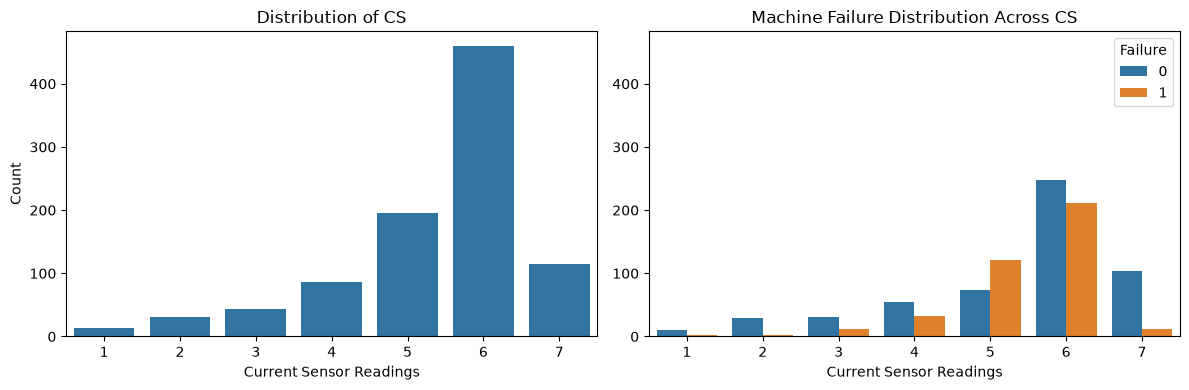

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4), sharey = True)

# distribution of all data
sns.countplot(x='CS', data=data, ax = ax1)
ax1.set_title('Distribution of CS')
ax1.set_xlabel('Current Sensor Readings')
ax1.set_ylabel('Count')

# stacked bars by fail or not
sns.countplot(x='CS', hue='fail', data=data, ax = ax2)
ax2.set_title('Machine Failure Distribution Across CS')
ax2.set_xlabel('Current Sensor Readings')
ax2.tick_params(labelleft = True)
plt.legend(title='Failure')

plt.tight_layout()
plt.show()

<div class = "notes">
    Note:
    <br> Current Sensor Readings data seems have normal distribution with most data falls in category 7.
    <br> The plot on the right shows that the distribution of fail data seems to align with the data.
</div>

## 6. Plotting the Distribution of VOC Volatile Organic Compounds

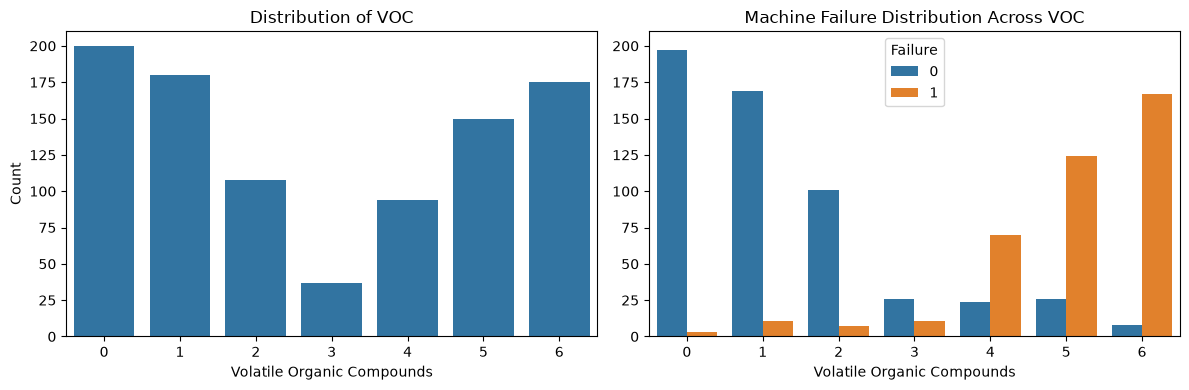

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4), sharey = True)

# distribution of all data
sns.countplot(x='VOC', data=data, ax = ax1)
ax1.set_title('Distribution of VOC')
ax1.set_xlabel('Volatile Organic Compounds')
ax1.set_ylabel('Count')

# stacked bars by fail or not
sns.countplot(x='VOC', hue='fail', data=data, ax = ax2)
ax2.set_title('Machine Failure Distribution Across VOC')
ax2.set_xlabel('Volatile Organic Compounds')
ax2.tick_params(labelleft = True)
plt.legend(title='Failure')

plt.tight_layout()
plt.show()

<div class = "notes">
    Note:
    <br> Volatile Organic Compounds data seems to split in the middle of value 3.
    <br> The plot on the right shows that the distribution of fail data seems to aggregate around the higher values.
</div>

## 7. Plotting the Distribution of IP Input Pressure

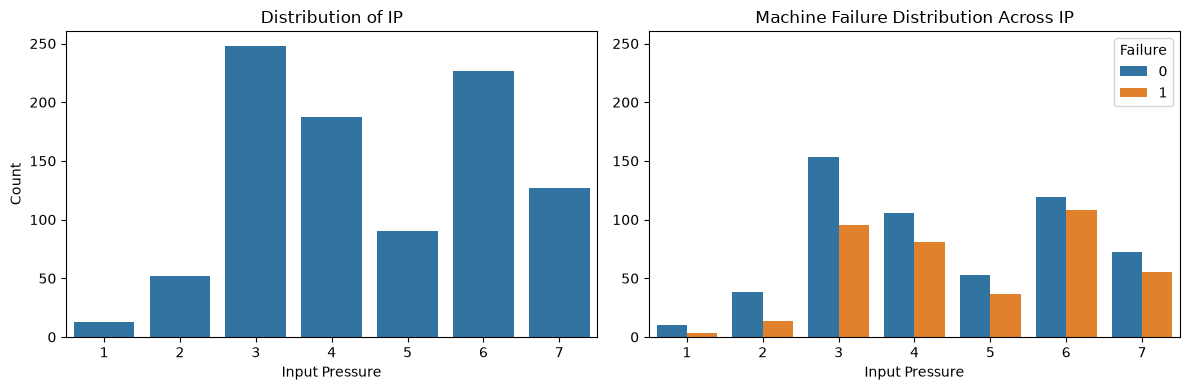

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4), sharey = True)

# distribution of all data
sns.countplot(x='IP', data=data, ax = ax1)
ax1.set_title('Distribution of IP')
ax1.set_xlabel('Input Pressure')
ax1.set_ylabel('Count')

# stacked bars by fail or not
sns.countplot(x='IP', hue='fail', data=data, ax = ax2)
ax2.set_title('Machine Failure Distribution Across IP')
ax2.set_xlabel('Input Pressure')
ax2.tick_params(labelleft = True)
plt.legend(title='Failure')

plt.tight_layout()
plt.show()

<div class = "notes">
    Note:
    <br> Input Pressure data seems to spread over two peaks, number 3 and 6.
    <br> The plot on the right shows that the distribution of fail data seems to align with the data distribution.
</div>

<div class = "notes">
    Notes:
    <br> All 6 columns with categorical data does not seem to have extreme outliers.
</div>

## 8. Plotting the Distribution of Columns with Contiuous Values

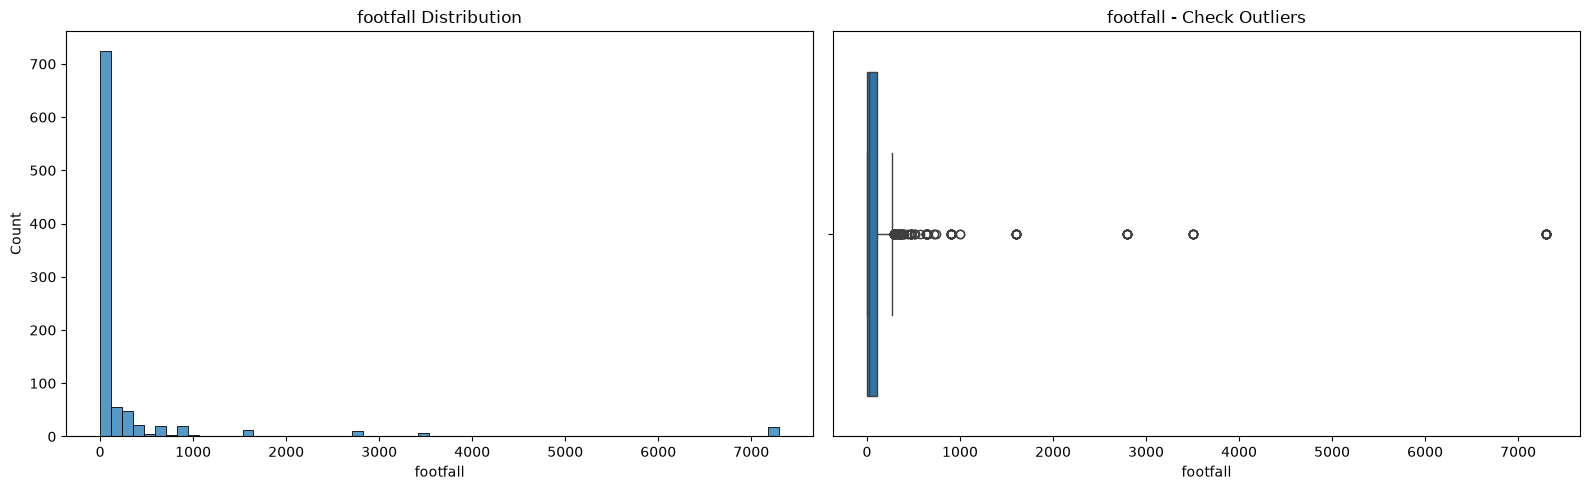

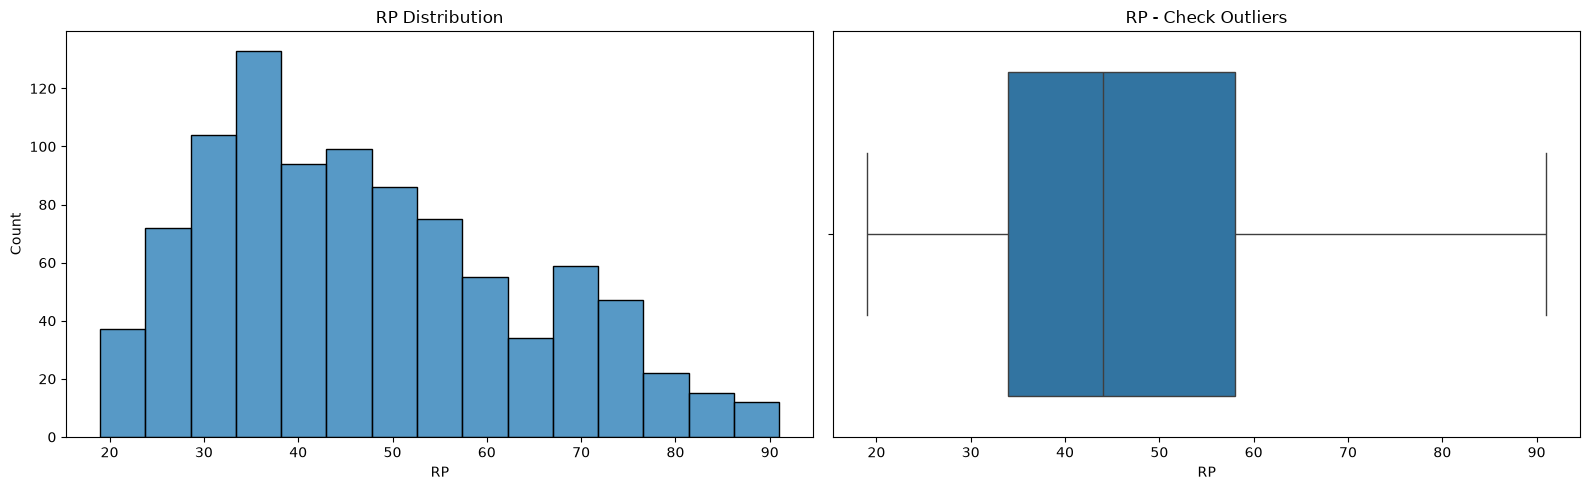

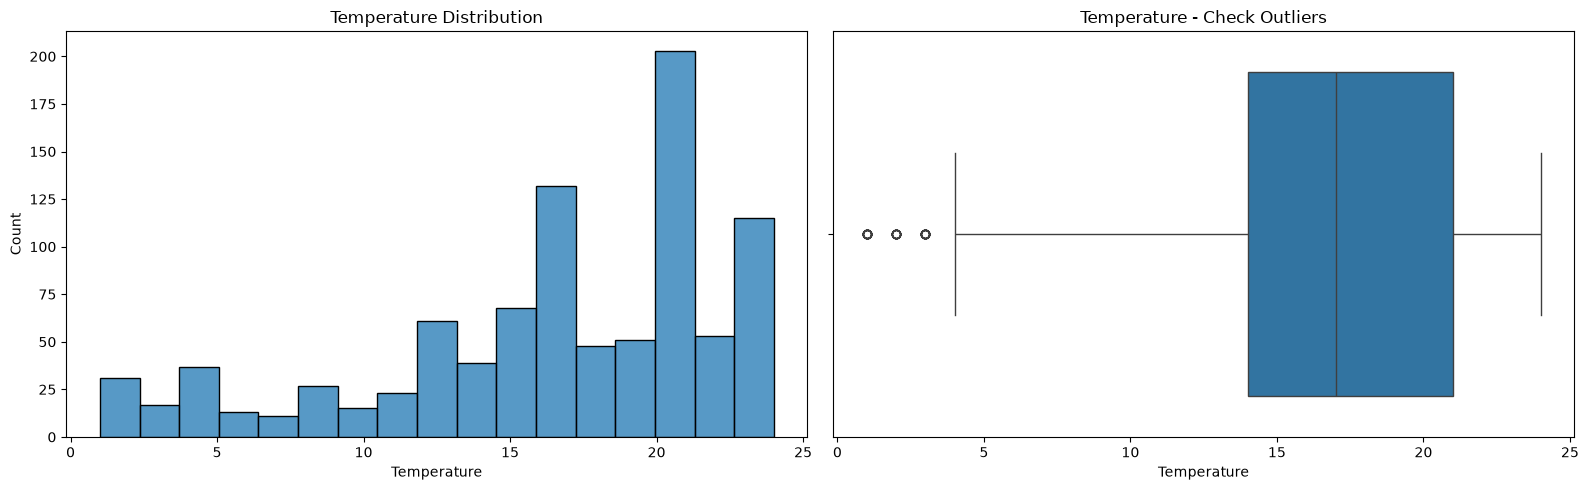

In [24]:
# set up an array of the columns with continuous values
cols = ['footfall', 'RP', 'Temperature']

# plot histogram for patterns and boxplot for anomalies
for col in cols:
    fig, axes = plt.subplots(1, 2, figsize = (16, 5))

    # histogram to observe distribution
    sns.histplot(data = data, x = col, ax = axes[0])
    axes[0].set_title(f"{col} Distribution")

    # boxplot to observe anomalies
    sns.boxplot(data = data, x = col, ax = axes[1])
    axes[1].set_title(f"{col} - Check Outliers")

    plt.tight_layout()
    plt.show()

<div class = "notes">
    Notes:
    <br> The distribution of footfall is quite imbalanced.
    <br> Other two features seem fine.
</div>

## 9. Pairplot for Relationships of Columns with Continuous Values

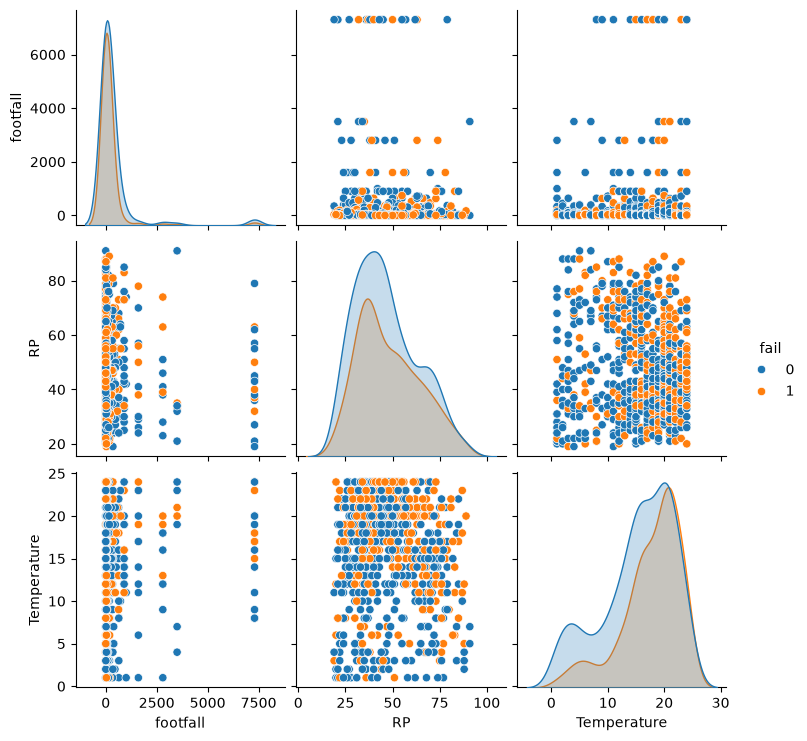

In [25]:
sns.pairplot(data[['footfall', 'RP', 'Temperature', 'fail']], hue = 'fail')
plt.show()

## 10. Correlation Between Features

<Axes: >

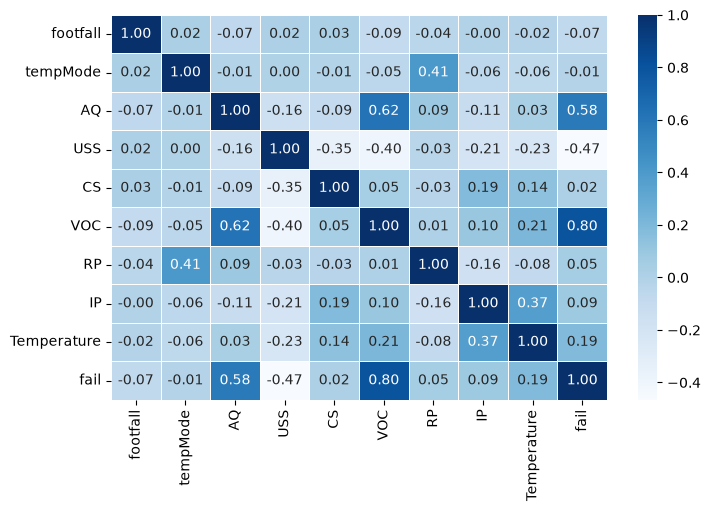

In [26]:
corr = data.corr()
plt.figure(figsize = (8, 5))
sns.heatmap(corr, annot = True, cmap = 'Blues', fmt = ".2f", linewidths = -.5)

<div class = "notes">
    Notes:
    <br> There is no obviously strong correlation between the input variables. No action is needed to drop strongly correlated columns.
    <br> AQ and VOC seem to have strong corrletions with fail.
</div>

# Prepare the Data

<div class = "notes">
    Notes:
    <br> The dataset seem clean enough. No actions is needed to remove outliers, null values, or missing values.
    <br> No feature engineering is needed.
</div>

# Identify Predictors, Target and Type of Modelling

In [27]:
# identify predictors X

features = ['footfall', 'tempMode', 'AQ', 'USS', 'CS', 'VOC', 'RP', 'IP', 'Temperature']

X = data[features].copy()

# idenfity target varaiable y
target = 'fail'

y = data[target].copy()

<div class = "notes">
    Notes
    <br> This will be a supervised modelling as the target variable is known.
    <br> It will be a binary classification modelling as there are only two values in the target variable.
</div>

# Split the Data

In [28]:
# create training and testing subsets 80/20 split

X_train, X_test, y_train, y_test = train_test_split(
                                                X, y,
                                                test_size = 0.2,
                                                random_state = 42,
                                                stratify = y # stratify because footfall data is imbalanced
)

In [29]:
# initialise the scaler

scaler = StandardScaler()

# use fit_transform on training data
X_train_scaled = scaler.fit_transform(X_train)

# use transform on test data
X_test_scaled = scaler.transform(X_test)

# Define a Model - Model 1

In [30]:
# first use DecisionTree

model1 = DecisionTreeClassifier()

# Fit Model 1

In [31]:
model1.fit(X_train_scaled, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

# Evaluate Model 1 Train Model

In [32]:
# define a function to evaluate models in this notebook

## reference: Institute Of Data Lab Exercise 7.1.1

def show_summary_report(actual, prediction):

    if isinstance(actual, pd.Series):
        actual = actual.values.astype(int)
    prediction = prediction.astype(float)
    prediction_int = np.round(prediction)

    print('Accuracy : %.4f [TP / N]         Best: 1, Worst: 0' %
          accuracy_score(actual, prediction_int))
    msg = '           Proportion of predicted labels that match the true labels.'
    print(msg)
    print('Precision: %.4f [TP / (TP + FP)] Best: 1, Worst: 0' %
          precision_score(actual, prediction_int))
    msg = '           Not to label a negative sample as positive.'
    print(msg)
    print('Recall   : %.4f [TP / (TP + FN)] Best: 1, Worst: 0' %
          recall_score(actual, prediction_int))
    msg = '           Find all the positive samples.'
    print(msg)
    print('ROC AUC  : %.4f                  Best: 1, Worst: < 0.5' %
          roc_auc_score(actual, prediction))
    print('-' * 80)
    print('TP: True Positives, FP: False Positives,')
    print('TN: True Negatives, FN: False Negatives,')
    print('N: Number of samples')

    # Confusion Matrix
    mat = confusion_matrix(actual, prediction_int)

    # Precision/Recall
    precision, recall, _ = precision_recall_curve(actual, prediction)

    # Compute ROC curve and ROC area
    fpr, tpr, _ = roc_curve(actual, prediction)
    roc_auc = auc(fpr, tpr)

    # plot
    fig, ax = plt.subplots(1, 3, figsize=(18, 6))
    fig.subplots_adjust(left=0.02, right=0.98, wspace=0.2)

    # Confusion Matrix
    cm_labels = ['Work', 'Fail']
    sns.heatmap(mat.T, square=True, annot=True, fmt='d',
                cbar=False, cmap='Blues', ax=ax[0], xticklabels = cm_labels, yticklabels = cm_labels)

    ax[0].set_title('Confusion Matrix')
    ax[0].set_xlabel('True label')
    ax[0].set_ylabel('Predicted label')

    # Precision/Recall
    step_kwargs = {'step': 'post'}
    ax[1].step(recall, precision, color='b', alpha=0.2, where='post')
    ax[1].fill_between(recall, precision, alpha=0.2, color='b', **step_kwargs)
    ax[1].set_ylim([0.0, 1.0])
    ax[1].set_xlim([0.0, 1.0])
    ax[1].set_xlabel('Recall')
    ax[1].set_ylabel('Precision')
    ax[1].set_title('2-class Precision-Recall curve')

    # ROC
    ax[2].plot(fpr, tpr, color='darkorange', lw=2,
               label='ROC curve (AUC = %0.2f)' % roc_auc)
    ax[2].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax[2].set_xlim([0.0, 1.0])
    ax[2].set_ylim([0.0, 1.0])
    ax[2].set_xlabel('False Positive Rate')
    ax[2].set_ylabel('True Positive Rate')
    ax[2].set_title('Receiver Operating Characteristic')
    ax[2].legend(loc='lower right')

    plt.show()

In [33]:
# calculate prediction target y using Model 1 training data subset

y_train_pred1 = model1.predict_proba(X_train_scaled)[:,1]

Accuracy : 1.0000 [TP / N]         Best: 1, Worst: 0
           Proportion of predicted labels that match the true labels.
Precision: 1.0000 [TP / (TP + FP)] Best: 1, Worst: 0
           Not to label a negative sample as positive.
Recall   : 1.0000 [TP / (TP + FN)] Best: 1, Worst: 0
           Find all the positive samples.
ROC AUC  : 1.0000                  Best: 1, Worst: < 0.5
--------------------------------------------------------------------------------
TP: True Positives, FP: False Positives,
TN: True Negatives, FN: False Negatives,
N: Number of samples


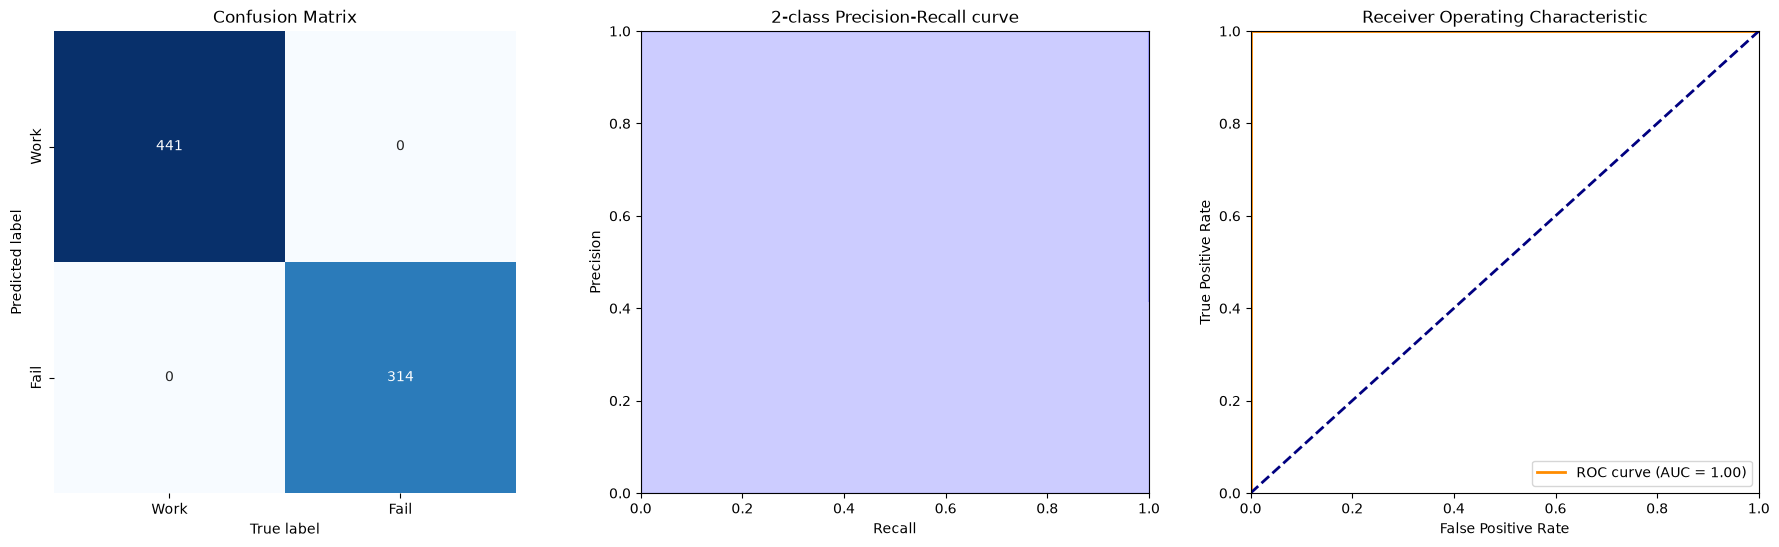

In [34]:
# use the function to evaluate Model 1 training model

show_summary_report(y_train, y_train_pred1)

# Evaluate Model 1 Test Model

In [35]:
# calculate prediction target y using Model 1 test data subset

y_test_pred1 = model1.predict_proba(X_test_scaled)[:,1]

Accuracy : 0.8624 [TP / N]         Best: 1, Worst: 0
           Proportion of predicted labels that match the true labels.
Precision: 0.8354 [TP / (TP + FP)] Best: 1, Worst: 0
           Not to label a negative sample as positive.
Recall   : 0.8354 [TP / (TP + FN)] Best: 1, Worst: 0
           Find all the positive samples.
ROC AUC  : 0.8586                  Best: 1, Worst: < 0.5
--------------------------------------------------------------------------------
TP: True Positives, FP: False Positives,
TN: True Negatives, FN: False Negatives,
N: Number of samples


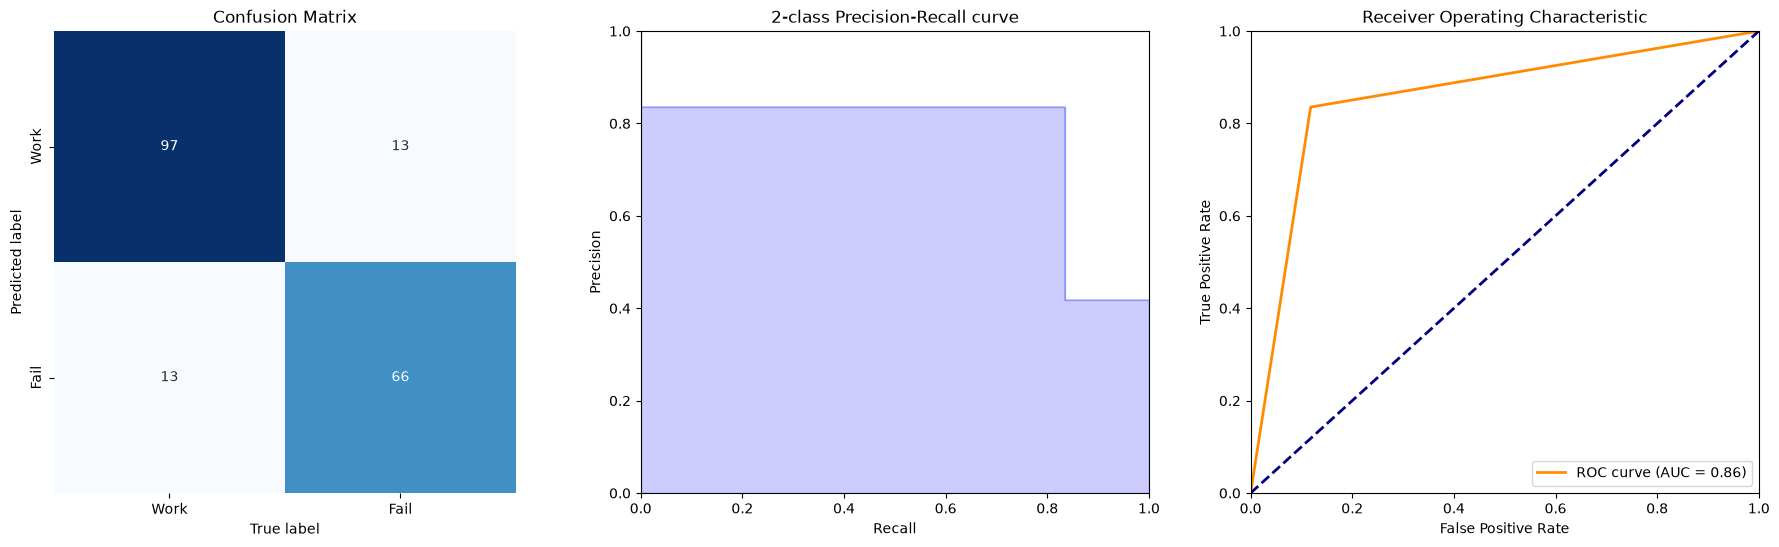

In [36]:
# use the function to evaluate Model 1 test model

show_summary_report(y_test, y_test_pred1)

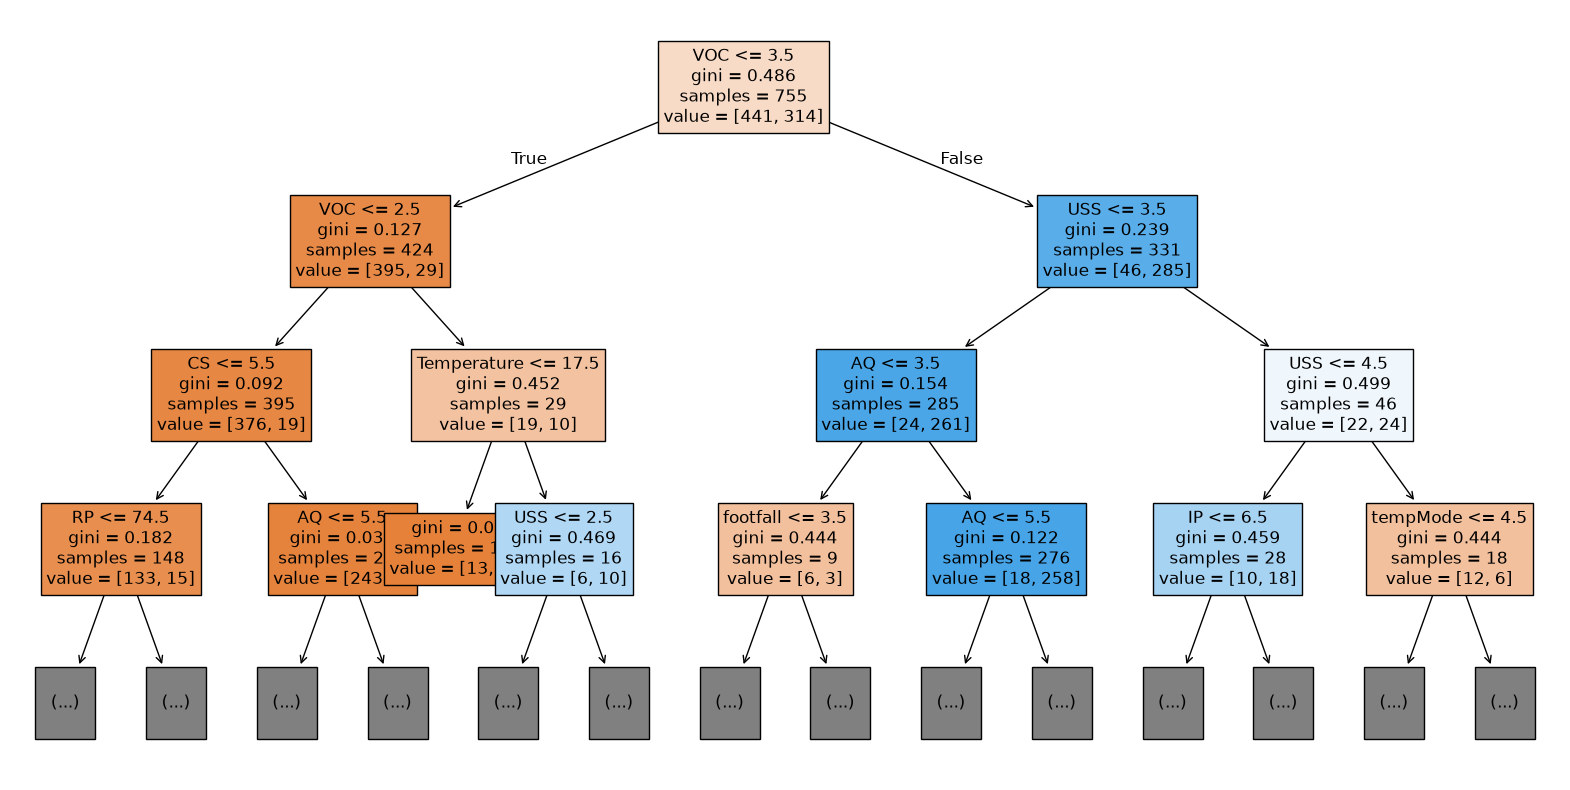

In [37]:
# plot the decision tree with only 3 splits
## change the fit from X_train_scaled to X_train for ease of interpretation
plt.figure(figsize = (20, 10))
tree.plot_tree(model1.fit(X_train, y_train), feature_names = features, max_depth = 3, fontsize = 12, filled = True)
plt.show()

In [38]:
# check a text representation of the tree
## change the fit from X_train_scaled to X_train for ease of interpretation
print(export_text(model1.fit(X_train, y_train), feature_names = features, show_weights = True))

|--- VOC <= 3.50
|   |--- VOC <= 2.50
|   |   |--- CS <= 5.50
|   |   |   |--- RP <= 74.50
|   |   |   |   |--- USS <= 3.50
|   |   |   |   |   |--- Temperature <= 15.50
|   |   |   |   |   |   |--- weights: [22.00, 0.00] class: 0
|   |   |   |   |   |--- Temperature >  15.50
|   |   |   |   |   |   |--- RP <= 40.50
|   |   |   |   |   |   |   |--- RP <= 35.50
|   |   |   |   |   |   |   |   |--- RP <= 25.00
|   |   |   |   |   |   |   |   |   |--- weights: [0.00, 1.00] class: 1
|   |   |   |   |   |   |   |   |--- RP >  25.00
|   |   |   |   |   |   |   |   |   |--- tempMode <= 0.50
|   |   |   |   |   |   |   |   |   |   |--- Temperature <= 22.00
|   |   |   |   |   |   |   |   |   |   |   |--- weights: [2.00, 0.00] class: 0
|   |   |   |   |   |   |   |   |   |   |--- Temperature >  22.00
|   |   |   |   |   |   |   |   |   |   |   |--- weights: [0.00, 1.00] class: 1
|   |   |   |   |   |   |   |   |   |--- tempMode >  0.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [3.00

# Pruning DecisionTree Model 1

## Pruning by finding cost_complexity_pruning_path

In [39]:
# extract cost-complexity values

ccp_path = model1.cost_complexity_pruning_path(X_train_scaled, y_train)

# set kfold

kfold = skm.KFold(10, random_state = 1, shuffle = True)

In [40]:
# extract an optimal value by cross-validation

grid = skm.GridSearchCV(model1,
    {'ccp_alpha': ccp_path.ccp_alphas},
    refit = True,
    cv = kfold,
    scoring = 'accuracy'
)

grid.fit(X_train_scaled, y_train)

print(grid.best_score_)
print(grid.best_estimator_.tree_.n_leaves)

0.893982456140351
2


<div class = "notes">
    NOTE
    <br>This best estimation of number of leaves looks odd. 
</div>

## Pruning by tuning hyperparameters

In [41]:
# set up parameter grid

param_grid = {
    'max_depth': range(1, 25, 1),
    'min_samples_leaf': range(1, 20, 2),
    'min_samples_split': range(2, 20, 2),
    'criterion': ["entropy", "gini"]
}


# define a DecisionTree model
tune_DT_ = DecisionTreeClassifier()

# set grid search
DT_grid_search_ = GridSearchCV(estimator=tune_DT_, param_grid=param_grid, 
                           cv=5, verbose=True)

# fit the model with X_train and y_train
DT_grid_search_.fit(X_train_scaled, y_train)

print(f"The best accuracy is {DT_grid_search_.best_score_:.4f}")
print(f"The best hyperparameter(s) is/are: {DT_grid_search_.best_estimator_}")

Fitting 5 folds for each of 4320 candidates, totalling 21600 fits
The best accuracy is 0.9007
The best hyperparameter(s) is/are: DecisionTreeClassifier(max_depth=1)


<div class = "notes">
    NOTE
    <br>This best hyperparameter estimation looks odd. I shall explore other learning models.
</div>

# Find algorithms with best accuracy

In [42]:
# define models with all classification models to be considered
models = {
    'Random Forest': RandomForestClassifier(random_state = 42,),
    'Gradient Boosting': GradientBoostingClassifier(random_state = 42,),
    'AdaBoost': AdaBoostClassifier(random_state = 42,),
    'Bagging': BaggingClassifier(random_state = 42,),
    'Decision Tree': DecisionTreeClassifier(random_state = 42,),
    'K-Nearest Neighbors': KNeighborsClassifier()
}

In [43]:
# create a function to fit models while going through for loop and evaluating models

def evaluate_model(X_train, X_test, y_train, y_test):
    result = []
    for name, model in models.items():
        model.fit(X_train, y_train)
        y_test_pred = model.predict(X_test)
        accuracy_ = accuracy_score(y_test, y_test_pred)
        result.append((name, accuracy_))
    # sort models by accuracy
    result.sort(key = lambda x: x[1], reverse = True)
    return result
 


In [44]:
# apply the evaluate function to our models
results = evaluate_model(X_train_scaled, X_test_scaled, y_train, y_test)

print("Model Performance:")
for name, acc in results:
    print(f"Model: {name} has achieved accuracy of {acc:.4f}")

Model Performance:
Model: Random Forest has achieved accuracy of 0.9259
Model: AdaBoost has achieved accuracy of 0.9153
Model: Gradient Boosting has achieved accuracy of 0.9101
Model: K-Nearest Neighbors has achieved accuracy of 0.8995
Model: Bagging has achieved accuracy of 0.8942
Model: Decision Tree has achieved accuracy of 0.8677


# Evaluate RandomForest Classifier on Test Data

In [45]:
# set up RandomForest Classifier model
model2 = RandomForestClassifier(random_state=42)

In [46]:
# fit training dataset
model2.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [47]:
# calculate prediction target y using Model 2 test data subset

y_test_pred2 = model2.predict_proba(X_test_scaled)[:,1]

Accuracy : 0.9259 [TP / N]         Best: 1, Worst: 0
           Proportion of predicted labels that match the true labels.
Precision: 0.9012 [TP / (TP + FP)] Best: 1, Worst: 0
           Not to label a negative sample as positive.
Recall   : 0.9241 [TP / (TP + FN)] Best: 1, Worst: 0
           Find all the positive samples.
ROC AUC  : 0.9783                  Best: 1, Worst: < 0.5
--------------------------------------------------------------------------------
TP: True Positives, FP: False Positives,
TN: True Negatives, FN: False Negatives,
N: Number of samples


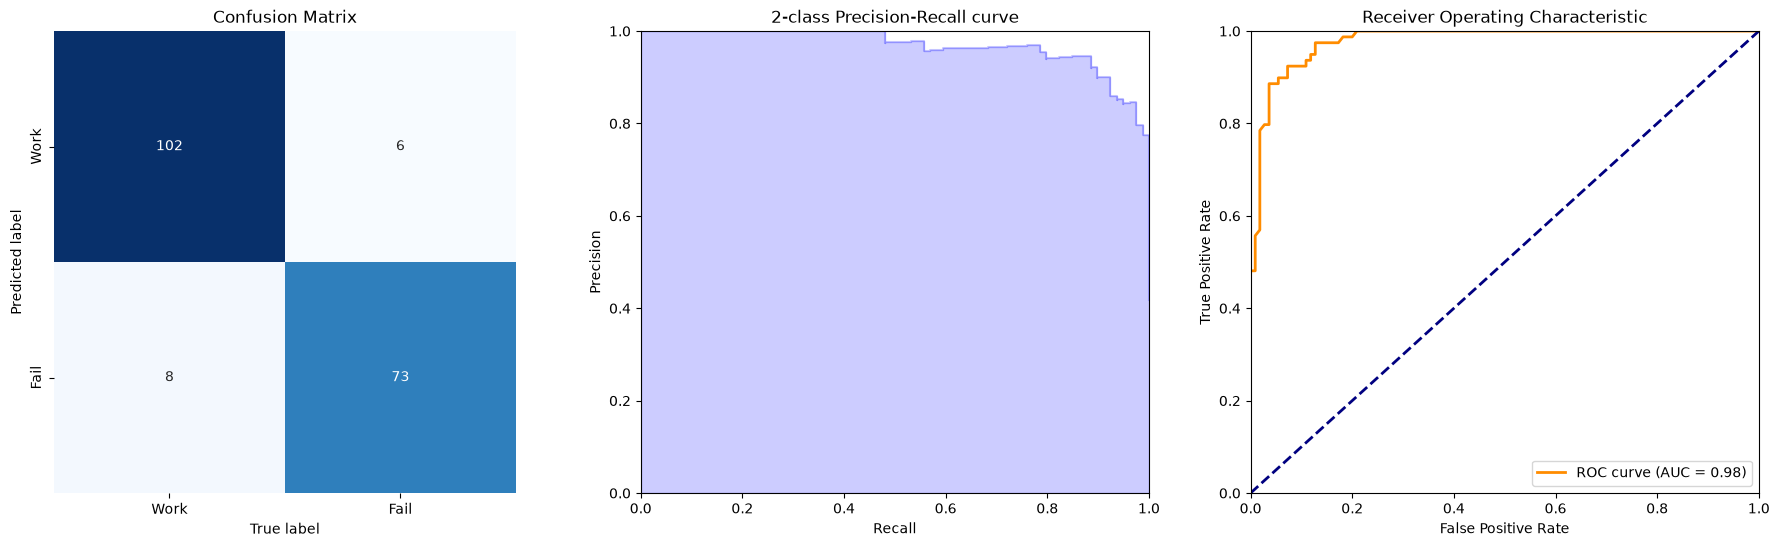

In [48]:
# use the function to evaluate Model 2 test model

show_summary_report(y_test, y_test_pred2)

<div class = "notes">
    NOTE:
    <br> The model has improved in predicting fail. Only has an error of 6/79. 
</div>

# Finding Feature Importances

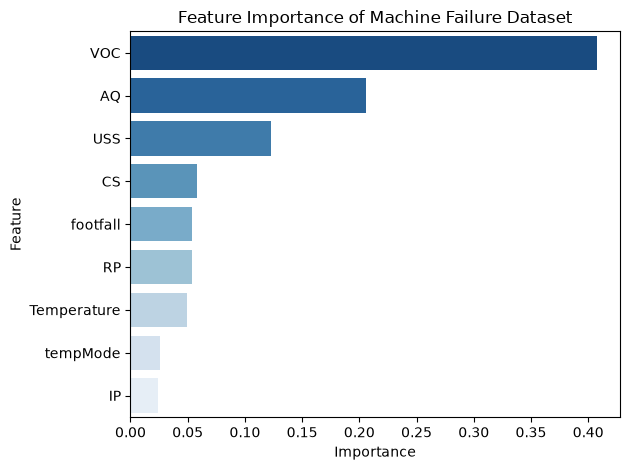

In [49]:
importances = model2.feature_importances_
# feature_names = features

# create a dataframe of feature importances
feat_imp_df = pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values(by = 'Importance', ascending = False)

# show it in a plot
base_palette = sns.color_palette('Blues', len(feat_imp_df))
sns.barplot(x = 'Importance', y = 'Feature', data = feat_imp_df, palette = 'Blues_r')
plt.title('Feature Importance of Machine Failure Dataset')
plt.tight_layout()
plt.show()

# Predictions Sampling

In [146]:
# make predictions using a randomly sampled observation in the existing dataset

n = data.sample(n = 1)
r = n[features]
print('*' * 50)
print("Sampled Observation:")
print(n.iloc[0])

sample1_prediction = model2.predict(r)
print('*' * 50)
print( f"Prediction from the RandomForest Classifier Model: {sample1_prediction}")

sample_prob = model2.predict_proba(r)[:,1]

print('*' * 50)
print( f"Probability of Failure is: {sample_prob}")
print('*' * 50)

**************************************************
Sampled Observation:
footfall       3500
tempMode          7
AQ                2
USS               2
CS                6
VOC               0
RP               34
IP                4
Temperature       4
fail              0
Name: 61, dtype: int64
**************************************************
Prediction from the RandomForest Classifier Model: [0]
**************************************************
Probability of Failure is: [0.33]
**************************************************


# CONCLUSION

We can predict the machine failure using a RandomForest Classifier model with an accuracy of 92.59%.

We can also set an alarm system with a trigger based on the tolerance threshold of failure probabilities.